# *Notum* against pseudotime (Fig. S22)

20261110 mouse pseudotime object in, the Fig. S22 *Notum* panel out: *Notum* (log1p counts per 10,000, from
`raw_counts`) against rank pseudotime for fibroblast and decidual nuclei, colored by group, with the mean of 25
equal-width bins and a bootstrap 95% CI of each bin mean (500 resamples, seed 0). Apoptotic nuclei (`decAp`) have
no pseudotime and are left out. The peak of the binned mean is printed, not drawn.

Input: the fib/dec pseudotime object, or the all-cells object with the same pseudotime; both give the same figure.
Layout follows the panel in the supplement. Writes the SVG, the bin table and a provenance file to `OUT`.

Font: Helvetica Neue if `FONT_FILE` points to it; otherwise DejaVu Sans (`DRAFT_FONT = True`).

In [1]:
# Parameters
MOUSE = "/n/lab_storage/eddy_lab/Lab/mckinley/data/20261110_mouse_only_eFib_dec_final_nick_pdt.h5ad"
OUT = "S22_notum_vs_pseudotime_files"  # a new folder; a relative path is next to the notebook

FONT_FILE = ""  # a Helvetica Neue font file, if there is one
DRAFT_FONT = True  # True: matplotlib's DejaVu Sans when Helvetica Neue is missing (the cluster); False: stop

## Setup

In [2]:
import datetime
import hashlib
import json
from io import BytesIO
from pathlib import Path

import matplotlib

# Figures go to files and previews are shown as PNGs, so the notebook backend's own rc settings
# never reach the saved SVG.
matplotlib.use("Agg")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from IPython.display import Image, display
from matplotlib import font_manager
from matplotlib.lines import Line2D

GENE = "Notum"
FONT = "Helvetica Neue"
DPI = 600  # resolution of the rasterized scatter layer embedded in the SVG
PREVIEW_DPI = 90  # notebook previews only

N_BINS = 25  # equal-width pseudotime bins of 0.04
N_BOOT = 500  # bootstrap resamples per bin
BOOT_SEED = 0

LABELS = {
    "x_axis": "Pseudotime",
    "y_axis": r"$\mathbfit{Notum}$ expression (log1p)",
}

FONT_SIZE = 9  # every piece of text: ticks, axis labels, legend

# Sizes and positions in inches, measured on the panel as laid out in the supplement figure
FIG_SIZE_IN = (5.2, 3.5)
AXES_IN = (0.676, 0.413, 3.947, 2.8)  # left, bottom, width, height
LEGEND_ANCHOR_IN = (4.696, 2.282)  # left edge and vertical center of the one-column legend, right of the axes
XLABEL_COORDS = (1.037, -0.102)  # axes fraction: right edge and top of "Pseudotime", past the end of the x axis
YLABEL_X = -0.10  # axes fraction

POINT_SIZE = 1.8  # pt^2; small and translucent so 42k overlapping points read as density
POINT_ALPHA = 0.55
TREND_LINE_WIDTH = 2.5
BAND_ALPHA = 0.25
LEGEND_MARKER_SIZE = 6

# Fibroblasts pink; decidual cells orange (dec1), blue (dec2) and purple (dec3). Groups are drawn in this order,
# later groups on top, so dec1 is drawn over the larger dec2 group.
GROUP_COLORS = {"eFib": "#C8668A", "dec2": "#4F86D6", "dec1": "#F2A93B", "dec3": "#7A68C0"}
LEGEND_ORDER = ["eFib", "dec1", "dec2", "dec3"]

FIGURE_FILE = "S22_notum_vs_pseudotime.svg"
BINS_FILE = "S22_notum_vs_pseudotime_bins.csv"
PROVENANCE_FILE = "S22_notum_vs_pseudotime_provenance.json"

BLACK_RC = {
    "text.color": "white",
    "axes.labelcolor": "white",
    "axes.edgecolor": "white",
    "xtick.color": "white",
    "ytick.color": "white",
    "figure.facecolor": "black",
    "axes.facecolor": "black",
    "savefig.facecolor": "black",
    "xtick.labelsize": FONT_SIZE,
    "ytick.labelsize": FONT_SIZE,
    "axes.labelsize": FONT_SIZE,
    "axes.linewidth": 1.0,
    "axes.spines.top": False,
    "axes.spines.right": False,
}


def set_up_font(font_file: str, draft: bool) -> str:
    """Register the manuscript font and set the shared rc; return the font used."""
    if font_file:
        font_manager.fontManager.addfont(font_file)
    font = FONT
    if FONT not in {f.name for f in font_manager.fontManager.ttflist}:
        if not draft:
            raise RuntimeError(f"{FONT!r} not found. Set FONT_FILE to a Helvetica Neue font file, or "
                               "DRAFT_FONT = True for matplotlib's default font.")
        font = "DejaVu Sans"  # bundled with matplotlib

    # rcdefaults first so a notebook backend's rc never leaks into the figure.
    matplotlib.rcdefaults()
    plt.rcParams.update(
        {
            "font.family": font,
            "mathtext.fontset": "custom",  # gene names in the text font
            "mathtext.rm": font,
            "mathtext.it": f"{font}:italic",
            "mathtext.bf": f"{font}:bold",
            "mathtext.bfit": f"{font}:italic:bold",  # bold italic gene name in the bold axis label
            "mathtext.cal": font,  # unused; set so matplotlib does not look for a cursive font
            "pdf.fonttype": 42,
            "svg.fonttype": "none",  # text stays editable text
            "svg.hashsalt": "xmens",  # stable element ids, so reruns give identical files
        }
    )
    return font


def sha256_of(path: Path) -> str:
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(1 << 24), b""):
            digest.update(block)
    return digest.hexdigest()


def save_svg(fig, path: Path) -> None:
    """Write an SVG with no date stamp."""
    fig.savefig(path, dpi=DPI, metadata={"Date": None})
    print(f"wrote {path.name}")


def show_preview(fig) -> None:
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=PREVIEW_DPI)
    display(Image(buffer.getvalue()))

## Inputs and checks

In [3]:
assert OUT, "set OUT to a new folder for the figure files"
OUT = Path(OUT)
OUT.mkdir(parents=True, exist_ok=True)
taken = [name for name in (FIGURE_FILE, BINS_FILE, PROVENANCE_FILE) if (OUT / name).exists()]
assert not taken, f"{OUT} already holds {taken}; set a new OUT (files are never overwritten)"

adata = sc.read_h5ad(MOUSE)
obs = adata.obs
root = str(adata.uns["pseudotime"]["root"])
counts = adata.layers["raw_counts"]  # raw counts, nuclei x genes
total_counts = np.asarray(counts.sum(axis=1), dtype=float).ravel()
gene_counts = counts[:, adata.var_names.get_loc(GENE)].toarray().ravel().astype(float)

mouse = obs[["cell_type", "cell_subtype", "timepoint", "pseudotime"]].copy()
for column in ("cell_type", "cell_subtype", "timepoint"):
    mouse[column] = mouse[column].astype(str)
mouse[GENE] = np.log1p(gene_counts / total_counts * 1e4)
if "total_counts" in obs:
    difference = np.abs(total_counts - obs["total_counts"].to_numpy(float)).max()
    print(f"counts per nucleus from raw_counts against obs['total_counts']: max difference {difference:.3g}")

# Fibroblast and decidual nuclei only; in the all-cells object the other cell types have no pseudotime.
mouse = mouse[mouse["cell_type"].isin(["eFib", "dec"])]

# Apoptotic decidual nuclei have no pseudotime and are left out; every other nucleus has one.
no_pseudotime = set(mouse.loc[mouse["pseudotime"].isna(), "cell_subtype"])
assert no_pseudotime <= {"decAp"}, f"nuclei without a pseudotime outside decAp: {no_pseudotime}"
cells = mouse[mouse["pseudotime"].notna()].copy()
assert cells.index[cells["pseudotime"].to_numpy().argmin()] == root, "the root does not have the lowest pseudotime"

# Fibroblast subtypes form one group (eFib); decidual subtypes keep their own.
cells["group"] = np.where(cells["cell_type"] == "eFib", "eFib", cells["cell_subtype"])
assert set(cells["group"]) == set(GROUP_COLORS), sorted(set(cells["group"]))
print(f"{len(cells):,} of {len(mouse):,} fibroblast and decidual nuclei have a pseudotime; {GENE} detected in "
      f"{int((cells[GENE] > 0).sum()):,} of them")
print(cells["group"].value_counts().to_dict())

counts per nucleus from raw_counts against obs['total_counts']: max difference 0
41,791 of 42,966 fibroblast and decidual nuclei have a pseudotime; Notum detected in 3,413 of them
{'eFib': 19169, 'dec2': 10846, 'dec1': 6318, 'dec3': 5458}


## Binned trend

Bins are [lo, hi); pseudotime 1.0 goes in the last bin.

In [4]:
def bin_means_with_ci(pseudotime: np.ndarray, expression: np.ndarray) -> pd.DataFrame:
    edges = np.linspace(0, 1, N_BINS + 1)
    bin_index = np.clip(np.digitize(pseudotime, edges) - 1, 0, N_BINS - 1)
    rng = np.random.default_rng(BOOT_SEED)

    rows = []
    for i in range(N_BINS):
        values = expression[bin_index == i]
        boot_means = values[rng.integers(0, len(values), size=(N_BOOT, len(values)))].mean(1)
        ci_lo, ci_hi = np.percentile(boot_means, [2.5, 97.5])
        rows.append(
            {
                "bin_center": (edges[i] + edges[i + 1]) / 2,
                "n_nuclei": len(values),
                "mean_log1p": values.mean(),
                "ci95_lo": ci_lo,
                "ci95_hi": ci_hi,
            }
        )
    return pd.DataFrame(rows)


bins = bin_means_with_ci(cells["pseudotime"].to_numpy(float), cells[GENE].to_numpy(float))

peak_bin = int(bins["mean_log1p"].idxmax())
peak_pseudotime = float(bins["bin_center"][peak_bin])
print(
    f"peak bin center {peak_pseudotime:.2f}: mean {bins['mean_log1p'][peak_bin]:.4f} log1p, "
    f"n = {int(bins['n_nuclei'][peak_bin]):,}"
)

# y range: 6% headroom above the highest nucleus, a sliver below zero so the zero row is not clipped
y_max = 1.06 * float(cells[GENE].max())

peak bin center 0.94: mean 0.4260 log1p, n = 1,672


## Drawing

font: DejaVu Sans


wrote S22_notum_vs_pseudotime.svg


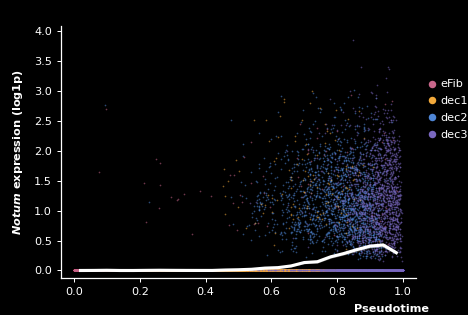

In [5]:
def paint_figure(fig) -> None:
    width, height = FIG_SIZE_IN
    left, bottom, axes_width, axes_height = AXES_IN
    ax = fig.add_axes([left / width, bottom / height, axes_width / width, axes_height / height])

    # Nuclei, colored by group; rasterized because 42k vector points make an unwieldy SVG
    for group, color in GROUP_COLORS.items():
        group_cells = cells[cells["group"] == group]
        ax.scatter(
            group_cells["pseudotime"],
            group_cells[GENE],
            s=POINT_SIZE,
            c=color,
            alpha=POINT_ALPHA,
            linewidths=0,
            rasterized=True,
        )

    # Bin means joined by straight lines (no smoothing), over the bootstrap 95% CI band
    ax.fill_between(bins["bin_center"], bins["ci95_lo"], bins["ci95_hi"], color="white", alpha=BAND_ALPHA, lw=0)
    ax.plot(bins["bin_center"], bins["mean_log1p"], color="white", lw=TREND_LINE_WIDTH)

    ax.set_xlim(-0.04, 1.04)
    ax.set_ylim(-0.03 * y_max, y_max)
    ax.set_xlabel(LABELS["x_axis"], loc="right", fontweight="bold")
    ax.xaxis.set_label_coords(*XLABEL_COORDS)
    ax.set_ylabel(LABELS["y_axis"], fontweight="bold")
    ax.yaxis.set_label_coords(YLABEL_X, 0.5)

    handles = [
        Line2D([], [], ls="", marker="o", ms=LEGEND_MARKER_SIZE, mfc=GROUP_COLORS[group], mec="none", label=group)
        for group in LEGEND_ORDER
    ]
    # One column to the right of the axes
    fig.legend(
        handles=handles,
        loc="center left",
        bbox_to_anchor=(LEGEND_ANCHOR_IN[0] / width, LEGEND_ANCHOR_IN[1] / height),
        borderaxespad=0,
        frameon=False,
        fontsize=FONT_SIZE,
        handlelength=0.8,
        handletextpad=0.4,
        labelspacing=0.6,
    )


font = set_up_font(FONT_FILE, DRAFT_FONT)
print(f"font: {font}")

with plt.rc_context(BLACK_RC):
    fig = plt.figure(figsize=FIG_SIZE_IN)
    paint_figure(fig)
    save_svg(fig, OUT / FIGURE_FILE)
    show_preview(fig)
    plt.close(fig)

## Bin table and provenance

In [6]:
bins.to_csv(OUT / BINS_FILE, index=False)
record = {
    "written": datetime.datetime.now().isoformat(timespec="seconds"),
    "notebook": "figures/S22_notum_vs_pseudotime.ipynb",
    "matplotlib": matplotlib.__version__,
    "font": font,
    "input": {"object": str(MOUSE), "object_sha256": sha256_of(Path(MOUSE)), "root": root,
              "n_fibroblast_decidual": int(len(mouse)), "n_with_pseudotime": int(len(cells)),
              "groups": {k: int(v) for k, v in cells["group"].value_counts().items()}},
    "expression": f"log1p({GENE} counts / counts per nucleus * 1e4), counts from layers['raw_counts']",
    "peak_pseudotime": peak_pseudotime,
    "outputs": {name: sha256_of(OUT / name) for name in (FIGURE_FILE, BINS_FILE)},
}
(OUT / PROVENANCE_FILE).write_text(json.dumps(record, indent=1) + "\n")
print(f"wrote {BINS_FILE}\nwrote {PROVENANCE_FILE}")

wrote S22_notum_vs_pseudotime_bins.csv
wrote S22_notum_vs_pseudotime_provenance.json
